# Relief Radar 02 — Modelling walkthrough

Protocol: train on complaints received before 2024, buffer year 2024 for drift context, test on 2025 onward. Features are known at receipt only; company identity enters through point-in-time history aggregates. Full audit: docs/leakage_audit.md.

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt

res = json.load(open('../reports/parts/model_results.json'))
rows = []
for name, block in res['models'].items():
    t = block['test']
    rows.append({'model': name, 'roc_auc': t['roc_auc'], 'pr_auc': t['pr_auc'],
                 'brier': t['brier'], 'log_loss': t['log_loss'],
                 'calibration_max_gap': block['calibration_max_abs_gap']})
headline = pd.DataFrame(rows).set_index('model')
print('test era:', res['protocol']['test'], '| test n:', f"{res['samples']['test_n']:,}",
      '| test base rate:', round(100 * res['samples']['test_base_rate'], 3), '%')
headline

test era: date_received >= 2025-01-01 | test n: 500,000 | test base rate: 0.509 %


,roc_auc,pr_auc,brier,log_loss,calibration_max_gap
model,,,,,
logistic_regression,0.985061,0.296583,0.004032,0.015221,0.011865
hist_gradient_boosting,0.989593,0.293559,0.004093,0.014301,0.014622
logistic_regression_balanced_sensitivity,0.988728,0.299093,0.018722,0.066731,0.508040


## Calibration (test era)

At a 0.5% base rate, calibration is the difference between a useful ranking and a useful probability. The class-weighted sensitivity model ranks about as well but its probabilities are uncalibrated by construction; it is reported as a sensitivity, never as a headline.

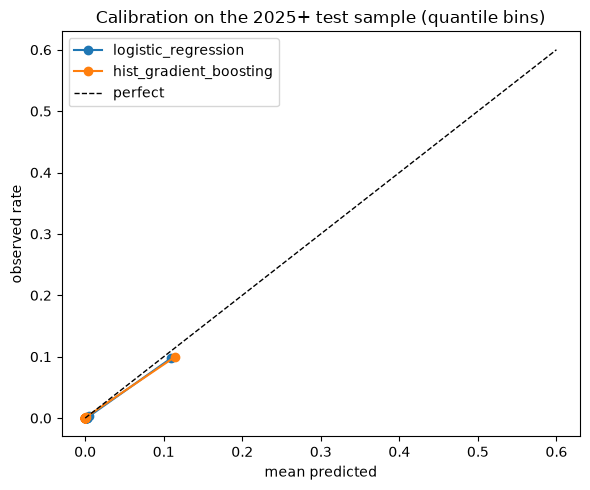

In [2]:
fig, ax = plt.subplots(figsize=(6, 5))
for name in ['logistic_regression', 'hist_gradient_boosting']:
    cal = pd.read_csv(f'../reports/parts/calibration_{name}.csv')
    ax.plot(cal['mean_predicted'], cal['observed_rate'], marker='o', label=name)
ax.plot([0, 0.6], [0, 0.6], 'k--', lw=1, label='perfect')
ax.set_xlabel('mean predicted'); ax.set_ylabel('observed rate')
ax.legend(); ax.set_title('Calibration on the 2025+ test sample (quantile bins)')
plt.tight_layout(); plt.show()

## Subgroup honesty check

The headline AUC is flattered by product mix: the test era is dominated by credit-reporting complaints, which almost never end in monetary relief. Within-product discrimination is the honest read.

In [3]:
sub = pd.read_csv('../reports/parts/subgroups_hist_gradient_boosting_product.csv')
sub[['product', 'n', 'positives', 'base_rate', 'roc_auc', 'pr_auc']].sort_values('n', ascending=False)

,product,n,positives,base_rate,roc_auc,pr_auc
0,Credit reporting or other personal consumer re...,448755,79,0.000176,0.979324,0.016474
1,Debt collection,23879,37,0.001549,0.918596,0.019894
2,Credit card,7436,1085,0.145912,0.800406,0.357812
3,Checking or savings account,7098,928,0.130741,0.712111,0.281315
4,"Money transfer, virtual currency, or money ser...",5241,215,0.041023,0.903332,0.190874
5,Mortgage,2329,46,0.019751,0.787484,0.050436
6,Vehicle loan or lease,1807,47,0.026010,0.754521,0.098000
7,Student loan,1364,6,0.004399,0.868679,0.035588
8,"Payday loan, title loan, personal loan, or adv...",1255,28,0.022311,0.876557,0.231732
9,Prepaid card,503,67,0.133201,0.842085,0.362893


## Does the consumer's own text help? (narrative arm)

In [4]:
arm = json.load(open('../reports/parts/narrative_results.json'))
comp = pd.DataFrame(arm['models']).T
print('sample:', arm['samples'])
print('bootstrap, combined minus structured AUC:', arm['combined_minus_structured_auc'])
comp[['roc_auc', 'pr_auc', 'brier']]

sample: {'train_n': 40000, 'train_base_rate': 0.03675, 'test_n': 20000, 'test_base_rate': 0.01735, 'train_population_n': 1685668, 'test_population_n': 1337036, 'train_n_with_text': 40000, 'test_n_with_text': 20000}
bootstrap, combined minus structured AUC: {'point_estimate': 0.0040537621684351155, 'bootstrap_95ci': [0.00044806968930306005, 0.007211785681678456], 'bootstrap_reps': 300}


,roc_auc,pr_auc,brier
structured_only_logistic,0.965381,0.299217,0.013809
text_only_logistic,0.954227,0.263847,0.014711
combined_logistic,0.969435,0.338871,0.013347
structured_only_histgb,0.958189,0.225097,0.015735


## Selection audit and crosswalk status

Narratives are opt-in: the audit quantifies how far the narrative-bearing minority can speak for all complaints. The EDGAR crosswalk status is reported exactly as measured.

In [5]:
audit = json.load(open('../reports/parts/selection_audit.json'))
print('audit population:', audit['population'])
print('within-cell check:', audit.get('within_cell_relief_diff'))
cross = json.load(open('../reports/parts/crosswalk_status.json'))
print('crosswalk:', cross.get('status'), '| CFPB companies:', cross.get('cfpb_companies'))

audit population: {'primary_rows_in_window': 16782339, 'narrative_rows_in_window': 3836347, 'narrative_share': 0.2285942978508538, 'relief_rate_narrative': 0.025826391616816727, 'relief_rate_no_narrative': 0.007290596193787235}
within-cell check: {'cells': 132, 'volume_weighted_mean_diff': 0.0022446552742253273, 'median_diff': 0.003442085234083706, 'share_cells_narrative_higher': 0.7575757575757576}
crosswalk: blocked | CFPB companies: 7639
